In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
# Load the dataset
df = pd.read_csv("/content/glass.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
df.shape

(214, 10)

In [ ]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [ ]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [ ]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [ ]:
# Select numerical features for clustering
X = df[['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']]
print("Features selected for clustering")

Features selected for clustering


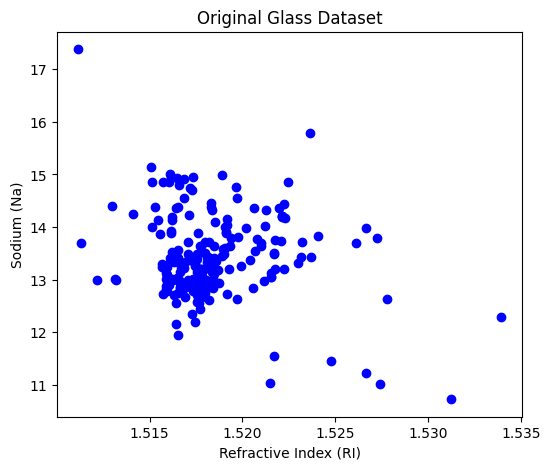

In [ ]:
# Visualize the original data points
plt.figure(figsize=(6,5))
plt.scatter(X['RI'], X['Na'], color='blue')
plt.xlabel("Refractive Index (RI)")
plt.ylabel("Sodium (Na)")
plt.title("Original Glass Dataset")
plt.show()

In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


In [ ]:
# Plot dendrogram using Single Linkage
linked = linkage(X_scaled, method='single')

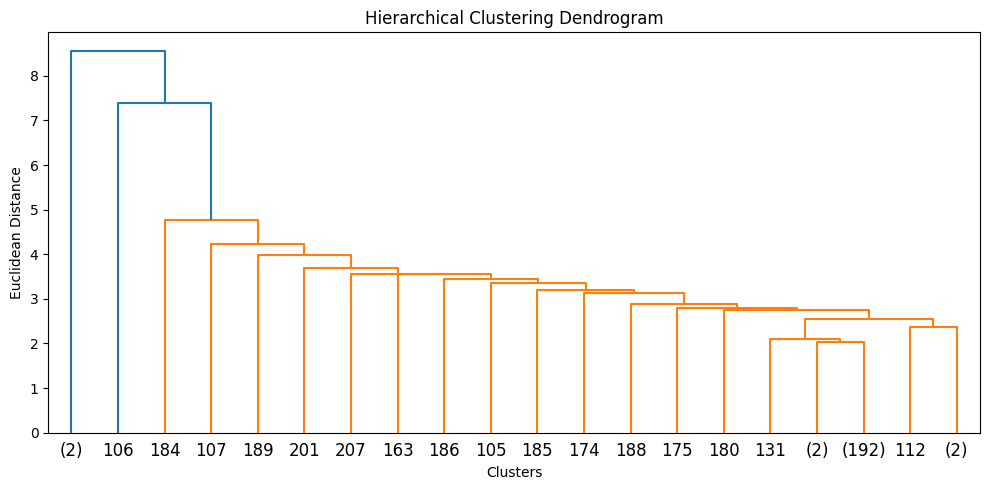

In [ ]:
# Plot a simple dendrogram
plt.figure(figsize=(10,5))
dendrogram(linked,truncate_mode='lastp',p=20,show_leaf_counts=True)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Clusters')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()

In [ ]:
# Initialize Agglomerative Clustering with 6 clusters
hc = AgglomerativeClustering(n_clusters=6, linkage='single')
labels = hc.fit_predict(X_scaled)
print("Model trained successfully")


Model trained successfully


In [ ]:
# Assign cluster labels to the dataset
df['Cluster'] = labels
df[['RI', 'Na', 'Cluster']].head()

,RI,Na,Cluster
0,1.52101,13.64,0
1,1.51761,13.89,0
2,1.51618,13.53,0
3,1.51766,13.21,0
4,1.51742,13.27,0


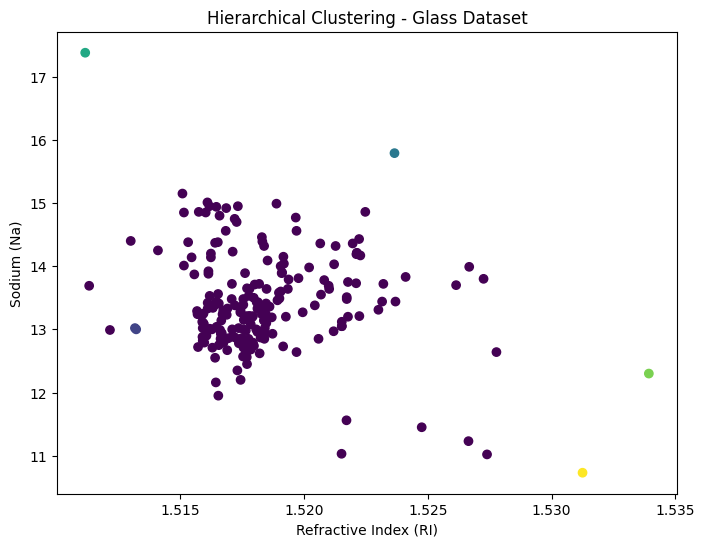

In [ ]:
# Visualize the clusters
plt.figure(figsize=(8,6))
plt.scatter(X['RI'], X['Na'], c=labels, cmap='viridis')
plt.xlabel("Refractive Index (RI)")
plt.ylabel("Sodium (Na)")
plt.title("Hierarchical Clustering - Glass Dataset")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)
db_score = davies_bouldin_score(X_scaled, labels)
print("Davies-Bouldin Index:", db_score)

Silhouette Score: 0.42341757905693195
Davies-Bouldin Index: 0.3166137515370105
